# Rain tomorrow: logistic regression

We use logistic regression to predict rain tomorrow. We choose its parameters by AP and its threshold by F1. LR will be the baseline for other models.

In [1]:
from pathlib import Path
import sys
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.base import clone
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits
from sklearn.model_selection import GridSearchCV
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, confusion_matrix,
    f1_score, average_precision_score, roc_auc_score,
    precision_recall_curve, PrecisionRecallDisplay, RocCurveDisplay,
    ConfusionMatrixDisplay,
)

ROOT = Path.cwd().resolve()
if not (ROOT / "src" / "data_prep.py").exists():
    ROOT = ROOT.parent
if not (ROOT / "src" / "data_prep.py").exists():
    raise RuntimeError("Run from the repository root or models directory")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.data_prep import (
    SEED, GAP_DAYS, load_clean, split_train_test, get_x_y,
    time_cv_splits, build_preprocessor,
)

warnings.filterwarnings("error", category=ConvergenceWarning)
OUT = ROOT / "results" / "logistic_regression"
OUT.mkdir(parents=True, exist_ok=True)
import sklearn

## Data and validation

Test starts on 2016-07-01. We leave a one-day gap between training and validation because the target is rain on the next day.

The first three time folds select C and class weights. The fourth year selects the threshold. We then fit on all training data. 

In [2]:
df = load_clean(ROOT / "data" / "weatherAUS.csv")

train, gap, test = split_train_test(df)
train, test = train.reset_index(drop=True), test.reset_index(drop=True)

assert not df.duplicated(["Date", "Location"]).any()
X, y = get_x_y(train)
cv = time_cv_splits(train["Date"])

assert train.Date.max() + pd.Timedelta(days=GAP_DAYS) < test.Date.min()
fold_rows = []
for k, (tr, va) in enumerate(cv, 1):
    assert set(tr).isdisjoint(va)
    assert train.Date.iloc[tr].max() + pd.Timedelta(days=GAP_DAYS) < train.Date.iloc[va].min()
    fold_rows.append(dict(fold=k, train_n=len(tr), validation_n=len(va),
                          train_end=train.Date.iloc[tr].max(),
                          validation_start=train.Date.iloc[va].min(),
                          validation_end=train.Date.iloc[va].max(),
                          rain_rate=y.iloc[va].mean()))
    
display(pd.DataFrame(fold_rows))
search_cv = cv[:-1]
threshold_train, threshold_val = cv[-1]

,fold,train_n,validation_n,train_end,validation_start,validation_end,rain_rate
0,1,58590,14112,2012-06-29,2012-07-01,2013-06-30,0.206278
1,2,72698,17463,2013-06-29,2013-07-01,2014-06-30,0.217374
2,3,90161,17292,2014-06-29,2014-07-01,2015-06-30,0.208015
3,4,107454,17356,2015-06-29,2015-07-01,2016-06-29,0.211454


## Class balance

0 = No Rain, 1 = Rain. We show all rows with a known target. Always predicting No Rain gives about 77.6% accuracy on these data, but F1 = 0. This shows why accuracy alone is not enough.

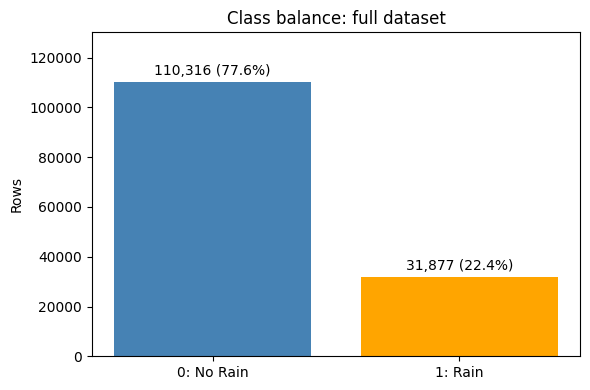

Always No Rain: full-dataset accuracy = 77.6%, F1 = 0.


In [3]:
counts = df["RainTomorrow"].value_counts().reindex([0, 1], fill_value=0)
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(["0: No Rain", "1: Rain"], counts, color=["steelblue", "orange"])
ax.bar_label(bars, labels=[f"{v:,} ({v / counts.sum():.1%})" for v in counts], padding=3)
ax.set(title="Class balance: full dataset", ylabel="Rows", ylim=(0, counts.max() * 1.18))
plt.tight_layout()
plt.show()
print(f"Always No Rain: full-dataset accuracy = {df.RainTomorrow.eq(0).mean():.1%}, F1 = 0.")

## Model and preprocessing

We try C = 0.01, 0.1, 1, 10, with and without class balancing. A smaller C means stronger regularization.

We fill numeric gaps with medians, add missing-value indicators and use StandardScaler. Categories use one-hot encoding. The pipeline learns these steps only from each training fold.

In [4]:
def make_pipeline(model):
    prep = build_preprocessor()
    prep.set_params(numeric=Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True)),("scale", StandardScaler()),]))
    
    return Pipeline([("prep", prep), ("model", model)])

pipe = make_pipeline(LogisticRegression(solver="lbfgs", max_iter=2000, random_state=SEED))
search = GridSearchCV(pipe, {"model__C": [0.01, 0.1, 1.0, 10.0],"model__class_weight": [None, "balanced"],
                            }, scoring="average_precision", cv=search_cv, n_jobs=1, refit=True, error_score="raise")

with threadpool_limits(limits=2):
    search.fit(X, y)
    
results = pd.DataFrame(search.cv_results_)
search_table = pd.DataFrame({
    "C": results.param_model__C,
    "class_weight": results.param_model__class_weight.fillna("none"),
    "mean_AP": results.mean_test_score,
    "std_AP": results.std_test_score,
    "rank": results.rank_test_score,
})

for k in range(len(search_cv)):
    search_table[f"fold_{k + 1}_AP"] = results[f"split{k}_test_score"]
    
search_table = search_table.sort_values("rank")
display(search_table.round(4))
search_table.to_csv(OUT / "search.csv", index=False)
print("Selected configuration:")
display(search_table.head(1))

,C,class_weight,mean_AP,std_AP,rank,fold_1_AP,fold_2_AP,fold_3_AP
4,1.00,none,0.6949,0.0171,1,0.6816,0.7191,0.6840
6,10.00,none,0.6948,0.0171,2,0.6816,0.7189,0.6840
2,0.10,none,0.6947,0.0172,3,0.6812,0.7190,0.6839
3,0.10,balanced,0.6916,0.0177,4,0.6774,0.7165,0.6809
5,1.00,balanced,0.6916,0.0175,5,0.6776,0.7163,0.6809
7,10.00,balanced,0.6915,0.0174,6,0.6776,0.7161,0.6808
0,0.01,none,0.6907,0.0175,7,0.6762,0.7153,0.6805
1,0.01,balanced,0.6886,0.0177,8,0.6737,0.7135,0.6786


Selected configuration:


,C,class_weight,mean_AP,std_AP,rank,fold_1_AP,fold_2_AP,fold_3_AP
4,1.0,none,0.69488,0.017149,1,0.681557,0.719092,0.683991


## Validation predictions and threshold

We choose the threshold with the highest F1 on the fourth validation year. If scores are equal, we take the higher threshold.

,model,fold,accuracy,specificity,precision,recall,f1,average_precision,roc_auc,role
0,Logistic Regression,1,0.8564,0.9531,0.7287,0.4844,0.5819,0.6816,0.8712,model selection
1,Logistic Regression,2,0.8570,0.9383,0.7175,0.5640,0.6316,0.7191,0.8818,model selection
2,Logistic Regression,3,0.8532,0.9498,0.7176,0.4854,0.5791,0.6840,0.8718,model selection
3,Logistic Regression,4,0.8522,0.9515,0.7270,0.4817,0.5795,0.6814,0.8672,threshold validation


accuracy        precision          \
                                             mean    std      mean     std   
model               role                                                     
Logistic Regression model selection        0.8555  0.002    0.7213  0.0064   
                    threshold validation   0.8522    NaN    0.7270     NaN   

                                          recall              f1          \
                                            mean     std    mean     std   
model               role                                                   
Logistic Regression model selection       0.5113  0.0457  0.5975  0.0295   
                    threshold validation  0.4817     NaN  0.5795     NaN   

                                         average_precision        roc_auc  \
                                                      mean    std    mean   
model               role                                                    
Logistic Regression model selection                 0.6949  0.021  0.8749   
                    threshold validation            0.6814    NaN  0.8672   

                                                 
                                            std  
model               role                         
Logistic Regression model selection       0.006  
                    threshold validation    NaN

Validation-selected F1 threshold: 0.3245


,threshold,precision,recall,f1
13429,0.3245,0.6175,0.6594,0.6378


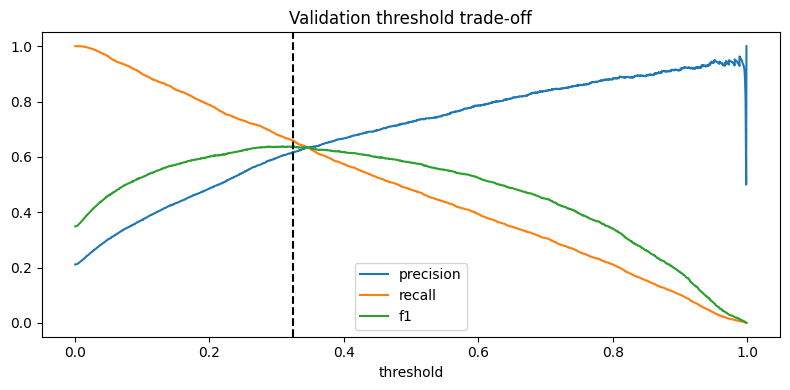

,threshold,accuracy,specificity,precision,recall,f1,average_precision,roc_auc
0,0.5000,0.8522,0.9515,0.7270,0.4817,0.5795,0.6814,0.8672
1,0.3245,0.8416,0.8905,0.6175,0.6594,0.6378,0.6814,0.8672


In [5]:
def metrics(y_true, probability, threshold=0.5):
    prediction = probability >= threshold
    tn, fp, fn, tp = confusion_matrix(y_true, prediction, labels=[0, 1]).ravel()
    return dict(accuracy=accuracy_score(y_true, prediction),
                specificity=tn / (tn + fp) if tn + fp else np.nan,
                precision=precision_score(y_true, prediction, zero_division=0),
                recall=recall_score(y_true, prediction, zero_division=0),
                f1=f1_score(y_true, prediction, zero_division=0),
                average_precision=average_precision_score(y_true, probability),
                roc_auc=roc_auc_score(y_true, probability))

rows, oof = [], []
for k, (tr, va) in enumerate(cv, 1):
    with threadpool_limits(limits=2):
        fitted = clone(search.best_estimator_).fit(X.iloc[tr], y.iloc[tr])
    probability = fitted.predict_proba(X.iloc[va])[:, 1]
    rows.append(dict(model="Logistic Regression", fold=k, **metrics(y.iloc[va], probability)))
    oof.append(pd.DataFrame({"row": va, "fold": k, "y": y.iloc[va].to_numpy(),
                             "probability": probability}))
    if k == len(cv):
        interpretation_model = fitted
cv_metrics = pd.DataFrame(rows)
cv_metrics["role"] = np.where(cv_metrics.fold == len(cv), "threshold validation", "model selection")
display(cv_metrics.round(4))
display(cv_metrics.groupby(["model", "role"])[["accuracy", "precision", "recall", "f1", "average_precision", "roc_auc"]].agg(["mean", "std"]).round(4))
cv_metrics.to_csv(OUT / "cv_metrics.csv", index=False)
oof = pd.concat(oof, ignore_index=True)

threshold_data = oof[oof.fold == len(cv)]
precision, recall, thresholds = precision_recall_curve(threshold_data.y, threshold_data.probability)
f1 = 2 * precision[:-1] * recall[:-1] / np.maximum(precision[:-1] + recall[:-1], 1e-15)

best_index = np.flatnonzero(f1 == f1.max())[-1]
threshold = float(thresholds[best_index])
threshold_table = pd.DataFrame({"threshold": thresholds, "precision": precision[:-1], "recall": recall[:-1], "f1": f1})
threshold_table.to_csv(OUT / "thresholds.csv", index=False)
oof.to_csv(OUT / "validation_predictions.csv", index=False)
print(f"Validation-selected F1 threshold: {threshold:.4f}")
display(threshold_table.iloc[[best_index]].round(4))
ax = threshold_table.plot(x="threshold", y=["precision", "recall", "f1"], figsize=(8, 4))
ax.axvline(threshold, color="black", linestyle="--")
ax.set_title("Validation threshold trade-off")
plt.tight_layout()
plt.show()
validation_comparison = pd.DataFrame([
    dict(threshold=t, **metrics(threshold_data.y, threshold_data.probability, t))
    for t in [0.5, threshold]
])
display(validation_comparison.round(4))
validation_comparison.to_csv(OUT / "threshold_validation_metrics.csv", index=False)
assert np.isclose(f1_score(threshold_data.y, threshold_data.probability >= threshold), f1[best_index])

## Final evaluation

We compare the chosen threshold with 0.50. F1 balances precision and recall. AP and ROC-AUC do not depend on the threshold.

,model,threshold,accuracy,specificity,precision,recall,f1,average_precision,roc_auc
0,Logistic Regression,0.5000,0.8403,0.9430,0.7256,0.4998,0.5919,0.6991,0.8626
1,Logistic Regression,0.3245,0.8242,0.8703,0.6096,0.6712,0.6389,0.6991,0.8626


Test rain prevalence: 0.2317


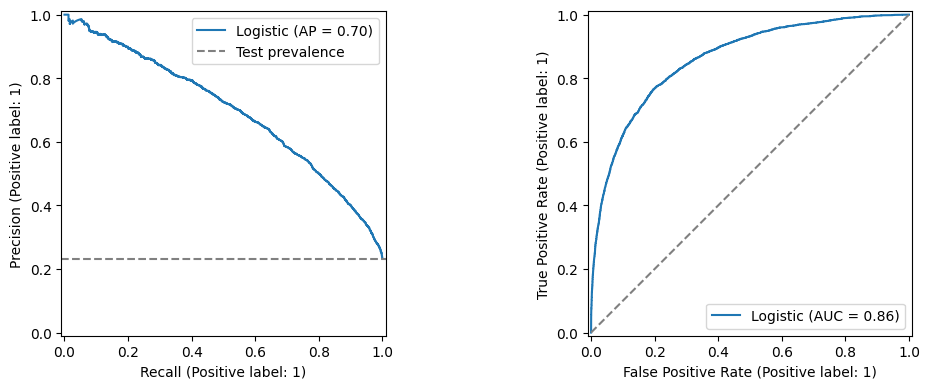

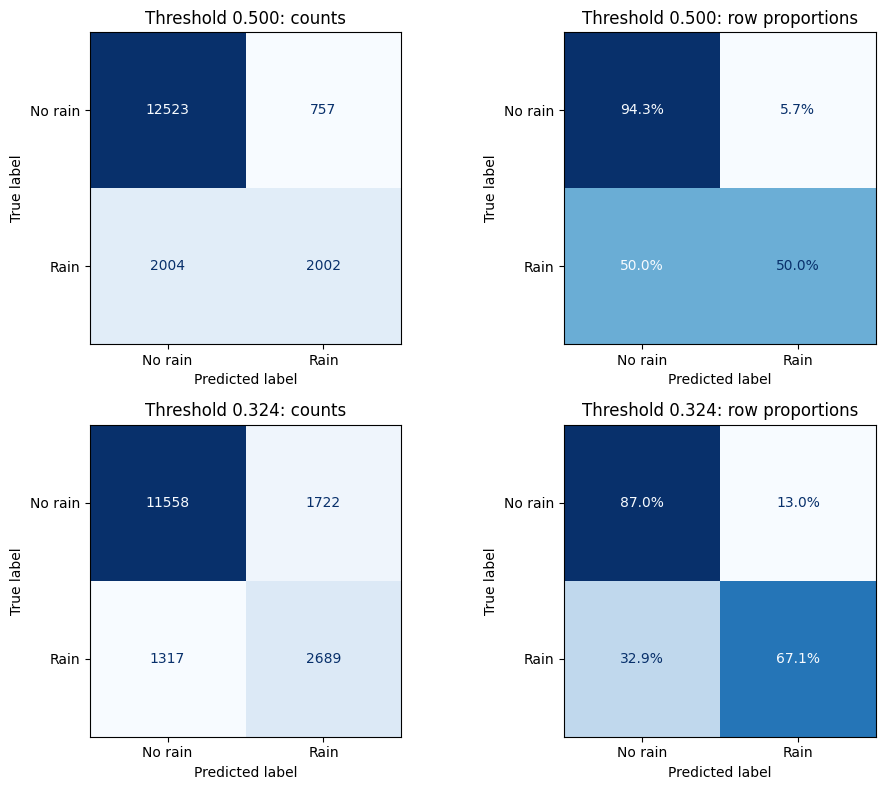

In [6]:
final_model = search.best_estimator_
X_test, y_test = get_x_y(test)
p_test = final_model.predict_proba(X_test)[:, 1]
test_metrics = pd.DataFrame([
    dict(model="Logistic Regression", threshold=0.5, **metrics(y_test, p_test)),
    dict(model="Logistic Regression", threshold=threshold, **metrics(y_test, p_test, threshold)),
])
display(test_metrics.round(4))
print(f"Test rain prevalence: {y_test.mean():.4f}")
test_metrics.to_csv(OUT / "test_metrics.csv", index=False)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
PrecisionRecallDisplay.from_predictions(y_test, p_test, ax=axes[0], name="Logistic")
axes[0].axhline(y_test.mean(), linestyle="--", color="gray", label="Test prevalence")
axes[0].legend()
RocCurveDisplay.from_predictions(y_test, p_test, ax=axes[1], name="Logistic")
axes[1].plot([0, 1], [0, 1], linestyle="--", color="gray")
plt.tight_layout()
plt.show()
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for row, t in enumerate([0.5, threshold]):
    for col, normalization in enumerate([None, "true"]):
        ConfusionMatrixDisplay.from_predictions(
            y_test, p_test >= t, labels=[0, 1], display_labels=["No rain", "Rain"],
            normalize=normalization, values_format="d" if normalization is None else ".1%",
            ax=axes[row, col], colorbar=False, cmap="Blues")
        axes[row, col].set_title(f"Threshold {t:.3f}: {'counts' if normalization is None else 'row proportions'}")
plt.tight_layout()
plt.show()

## Errors

We compare errors by station, month and missing data, and look at confident mistakes. These patterns show where the model struggles, not why each mistake happened.

In [7]:
errors = test.copy()
errors["probability"] = p_test
errors["prediction"] = (p_test >= threshold).astype(int)
errors["error"] = errors.prediction.ne(y_test)
errors["month"] = errors.Date.dt.month
errors["missing_weather"] = X_test.isna().any(axis=1)
errors["kind"] = np.select(
    [(y_test == 0) & (errors.prediction == 1), (y_test == 1) & (errors.prediction == 0)],
    ["false positive", "false negative"], default="correct")
errors.to_csv(OUT / "test_predictions.csv", index=False)
def group_errors(column):
    rows = []
    for value, group in errors.groupby(column):
        tp = ((group.RainTomorrow == 1) & (group.prediction == 1)).sum()
        fp = (group.kind == "false positive").sum()
        fn = (group.kind == "false negative").sum()
        negatives = (group.RainTomorrow == 0).sum()
        rows.append({column: value, "n": len(group), "rain_n": int(group.RainTomorrow.sum()),
                     "rain_rate": group.RainTomorrow.mean(), "error_rate": group.error.mean(),
                     "FP": fp, "FN": fn,
                     "recall": tp / (tp + fn) if tp + fn else np.nan,
                     "false_positive_rate": fp / negatives if negatives else np.nan})
    return pd.DataFrame(rows).sort_values("error_rate", ascending=False)
for column in ["Location", "month", "missing_weather"]:
    table = group_errors(column)
    table.to_csv(OUT / f"errors_by_{column}.csv", index=False)
    print(column)
    display(table.round(3))
example_columns = ["Date", "Location", "RainTomorrow", "probability", "Humidity3pm", "Rainfall", "Sunshine"]
print("Most confident false positives")
display(errors[errors.kind == "false positive"].nlargest(5, "probability")[example_columns])
print("Most confident false negatives")
display(errors[errors.kind == "false negative"].nsmallest(5, "probability")[example_columns])
coefficients = pd.Series(final_model.named_steps["model"].coef_[0],
                         index=final_model.named_steps["prep"].get_feature_names_out(), name="coefficient")
display(coefficients.reindex(coefficients.abs().sort_values(ascending=False).head(15).index).to_frame())
coefficients.to_csv(OUT / "coefficients.csv")

Location


,Location,n,rain_n,rain_rate,error_rate,FP,FN,recall,false_positive_rate
1,Albany,346,107,0.309,0.292,43,58,0.458,0.180
26,NorahHead,360,111,0.308,0.272,60,38,0.658,0.241
11,CoffsHarbour,360,104,0.289,0.269,73,24,0.769,0.285
24,Newcastle,346,90,0.260,0.269,34,59,0.344,0.133
14,GoldCoast,344,80,0.233,0.265,69,22,0.725,0.261
27,NorfolkIsland,317,104,0.328,0.262,51,32,0.692,0.239
45,Williamtown,334,101,0.302,0.260,46,41,0.594,0.197
23,MountGinini,359,105,0.292,0.248,60,29,0.724,0.236
8,Cairns,322,110,0.342,0.242,58,20,0.818,0.274
47,Wollongong,350,82,0.234,0.240,51,33,0.598,0.190


month


,month,n,rain_n,rain_rate,error_rate,FP,FN,recall,false_positive_rate
8,9,1444,492,0.341,0.228,178,151,0.693,0.187
6,7,1511,471,0.312,0.217,218,110,0.766,0.210
2,3,1480,412,0.278,0.186,164,111,0.731,0.154
0,1,1492,298,0.200,0.184,164,111,0.628,0.137
11,12,1417,292,0.206,0.181,151,106,0.637,0.134
9,10,1499,365,0.243,0.179,154,114,0.688,0.136
1,2,1345,284,0.211,0.178,137,103,0.637,0.129
7,8,1515,421,0.278,0.170,124,134,0.682,0.113
4,5,1501,293,0.195,0.148,113,109,0.628,0.094
10,11,1434,202,0.141,0.148,137,75,0.629,0.111


missing_weather


...

Most confident false positives


,Date,Location,RainTomorrow,probability,Humidity3pm,Rainfall,Sunshine
1125,2016-07-24,Ballarat,0,0.981559,99.0,1.4,NaN
10846,2017-02-12,CoffsHarbour,0,0.978811,69.0,0.0,NaN
15688,2017-05-23,Perth,0,0.969056,87.0,5.2,0.2
10880,2017-02-12,Williamtown,0,0.946258,78.0,0.0,NaN
17133,2017-06-22,PerthAirport,0,0.944520,75.0,37.8,0.0


Most confident false negatives


,Date,Location,RainTomorrow,probability,Humidity3pm,Rainfall,Sunshine
4327,2016-09-27,Woomera,1,0.005514,16.0,0.0,NaN
12534,2017-03-19,MelbourneAirport,1,0.007117,24.0,0.0,11.4
2442,2016-08-20,AliceSprings,1,0.008759,13.0,0.0,NaN
169,2016-07-04,MountGinini,1,0.009770,31.0,0.0,NaN
9710,2017-01-19,MelbourneAirport,1,0.010181,31.0,0.0,11.8


,coefficient
numeric__Humidity3pm,1.264517
numeric__Pressure3pm,-1.231252
categorical__Location_Katherine,-1.187123
categorical__Location_Wollongong,-0.905900
categorical__Location_MountGinini,-0.878698
numeric__Pressure9am,0.871846
categorical__Location_Adelaide,0.819990
categorical__Location_Townsville,-0.771110
categorical__Location_Penrith,0.754573
categorical__Location_SalmonGums,0.738031


## Permutation importance

We shuffle each feature and measure how much validation AP drops. The model is trained on earlier dates. We repeat this five times, error bars show the standard deviation.

A larger drop means the model relies more on that feature. Correlated features can replace each other. 

,feature,mean_AP_drop,std_AP_drop
9,Humidity3pm,0.2817,0.0050
11,Pressure3pm,0.2242,0.0049
5,WindGustSpeed,0.0971,0.0028
10,Pressure9am,0.0772,0.0018
17,Location,0.0416,0.0015
1,MaxTemp,0.0212,0.0017
13,Cloud3pm,0.0199,0.0022
15,Temp3pm,0.0197,0.0011
4,Sunshine,0.0134,0.0018
16,RainToday,0.0075,0.0012


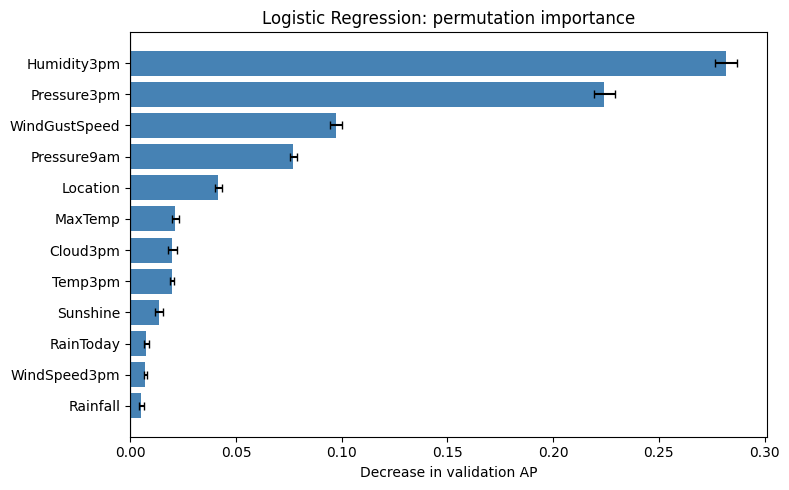

The largest AP drop is for Humidity3pm: 0.282.
This shows model reliance, not a causal effect on rainfall.


In [8]:
with threadpool_limits(limits=2):
    importance = permutation_importance(
        interpretation_model, X.iloc[threshold_val], y.iloc[threshold_val],
        scoring="average_precision", n_repeats=5, random_state=SEED, n_jobs=1,
    )
importance_table = pd.DataFrame({
    "feature": X.columns,
    "mean_AP_drop": importance.importances_mean,
    "std_AP_drop": importance.importances_std,
}).sort_values("mean_AP_drop", ascending=False)
importance_table.to_csv(OUT / "permutation_importance.csv", index=False)
display(importance_table.round(4))
plot_data = importance_table.head(12).sort_values("mean_AP_drop")
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(plot_data.feature, plot_data.mean_AP_drop, xerr=plot_data.std_AP_drop,
        color="steelblue", capsize=3)
ax.axvline(0, color="black", linewidth=0.8)
ax.set(xlabel="Decrease in validation AP", title="Logistic Regression: permutation importance")
plt.tight_layout()
plt.show()
top = importance_table.iloc[0]
print(f"The largest AP drop is for {top.feature}: {top.mean_AP_drop:.3f}.")
print("This shows model reliance, not a causal effect on rainfall.")

Humidity3pm had the largest AP drop (0.282), followed by Pressure3pm (0.224) and WindGustSpeed (0.097). The model relies most on these features. This does not show cause and effect. Shuffling correlated measurements can create unrealistic combinations.

## Conclusions

In [9]:
default = test_metrics.iloc[0]
tuned = test_metrics.iloc[1]
print(f"Test AP: logistic {default.average_precision:.3f}.")
print(f"At 0.50: precision {default.precision:.3f}, recall {default.recall:.3f}, F1 {default.f1:.3f}.")
print(f"At validation F1 threshold {threshold:.3f}: precision {tuned.precision:.3f}, recall {tuned.recall:.3f}, F1 {tuned.f1:.3f}.")
print("The F1 threshold balances precision and recall; it does not minimize a known financial cost.")
joblib.dump({"model": final_model, "threshold": threshold, "target": "RainTomorrow", "threshold_metric": "f1",
             "threshold_validation_start": str(train.Date.iloc[threshold_val].min().date()),
             "threshold_validation_end": str(train.Date.iloc[threshold_val].max().date()),
             "features": list(X.columns), "seed": SEED,
             "sklearn_version": sklearn.__version__, "best_params": search.best_params_},
            OUT / "logistic_rain_model.joblib")
print("Saved results to", OUT)

Test AP: logistic 0.699.
At 0.50: precision 0.726, recall 0.500, F1 0.592.
At validation F1 threshold 0.324: precision 0.610, recall 0.671, F1 0.639.
The F1 threshold balances precision and recall; it does not minimize a known financial cost.
Saved results to D:\kma\ml\ml_mini_project\results\logistic_regression


### Results

- C=1 without class balancing gave the best CV AP (0.6949). C=10 was almost the same.
- Test AP was 0.6991 and ROC-AUC was 0.8626.
- At 0.50, precision was 72.6%, recall 50.0% and F1 0.592. At the chosen threshold 0.324, they were 61.0%, 67.1% and 0.639. We catch more rain but get more false alarms.
- Albany had the highest error rate (29.2%) and recall of only 45.8%. The model does not work equally well at every station.